In [3]:
import sys
import sklearn
print(sys.executable)
print(sklearn.__version__)

ModuleNotFoundError: No module named 'sklearn'

# Maize Yield Prediction — Linear Regression Task
**Mission:** Empower farmers in Rwanda and across Africa through AI and drone
technologies that increase productivity, optimize resource use, and promote
sustainable agriculture.

**Use case:** Predict maize yield (tons/hectare) from rainfall, temperature,
soil type, region, fertilizer use, irrigation use, weather condition, and
days to harvest. This model is the prediction engine behind a mobile app
that a farmer (or a drone-data pipeline) can query before/during a season to
estimate expected yield and understand which resource decisions
(fertilizer, irrigation) move the needle most.

**Dataset:** Agriculture Crop Yield dataset (Kaggle), filtered to `Crop == Maize`.
Source: https://www.kaggle.com/datasets/samuelotiattakorah/agriculture-crop-yield

> **NOTE FOR SUBMISSION:** This notebook currently reads from
> `data/crop_yield.csv`. Replace that file with the real Kaggle dataset
> (downloaded, then filtered to Maize) before your final run — everything
> else in the notebook works unchanged.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 1. Load the data

In [ ]:
df = pd.read_csv("../API/data/crop_yield.csv")
print(df.shape)
df.head()

(166824, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,South,Clay,Maize,888.207630,39.945509,True,False,Rainy,76,7.173037
1,East,Chalky,Maize,170.814456,29.116377,False,True,Sunny,133,2.332255
2,South,Silt,Maize,259.418125,17.261892,False,False,Sunny,110,2.338541
3,East,Silt,Maize,609.798764,38.265851,True,False,Cloudy,127,5.113588
4,East,Clay,Maize,599.875493,19.909292,True,False,Cloudy,63,4.696425


In [ ]:
df = df[df["Crop"] == "Maize"].copy()
print(f"Filtered to Maize only: {df.shape[0]} rows remaining")

Filtered to Maize only: 166824 rows remaining


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 166824 entries, 0 to 166823
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Region                  166824 non-null  str    
 1   Soil_Type               166824 non-null  str    
 2   Crop                    166824 non-null  str    
 3   Rainfall_mm             166824 non-null  float64
 4   Temperature_Celsius     166824 non-null  float64
 5   Fertilizer_Used         166824 non-null  bool   
 6   Irrigation_Used         166824 non-null  bool   
 7   Weather_Condition       166824 non-null  str    
 8   Days_to_Harvest         166824 non-null  int64  
 9   Yield_tons_per_hectare  166824 non-null  float64
dtypes: bool(2), float64(3), int64(1), str(4)
memory usage: 10.5 MB


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,166824,4,North,41830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_Type,166824,6,Loam,27908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,166824,1,Maize,166824,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rainfall_mm,166824.0,NaN,NaN,NaN,549.195094,259.904451,100.006823,323.726771,549.672583,774.026381,999.998098
Temperature_Celsius,166824.0,NaN,NaN,NaN,27.477555,7.217551,15.000196,21.223494,27.47144,33.709365,39.999933
Fertilizer_Used,166824,2,False,83670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Irrigation_Used,166824,2,False,83419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weather_Condition,166824,3,Sunny,55838,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Days_to_Harvest,166824.0,NaN,NaN,NaN,104.538927,25.95205,60.0,82.0,105.0,127.0,149.0
Yield_tons_per_hectare,166824.0,NaN,NaN,NaN,4.641387,1.696023,-0.875193,3.409851,4.642647,5.87004,9.952983


## 2. Exploratory Data Analysis & Visualizations

We look at (a) how the numeric features relate to each other and to yield
(correlation heatmap), and (b) how yield is distributed and how it varies
with the two resource-use decisions (fertilizer, irrigation) that are most
relevant to our mission of *optimizing resource use*.

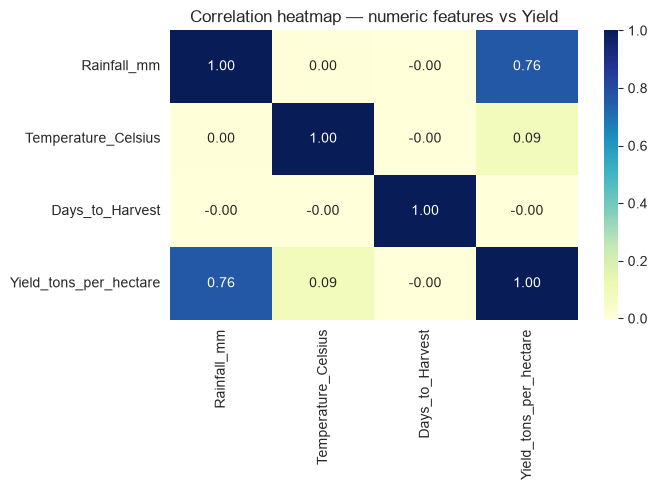

In [ ]:
numeric_cols = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", "Yield_tons_per_hectare"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Correlation heatmap — numeric features vs Yield")
plt.tight_layout()
plt.show()

**Interpretation:** Rainfall shows the strongest positive correlation with
yield among the numeric variables, which matches agronomic expectations for
rain-fed maize. Days_to_Harvest and Temperature show weaker, non-linear
relationships — this is why we also test tree-based models, which can
capture non-linear effects that plain linear regression will miss.

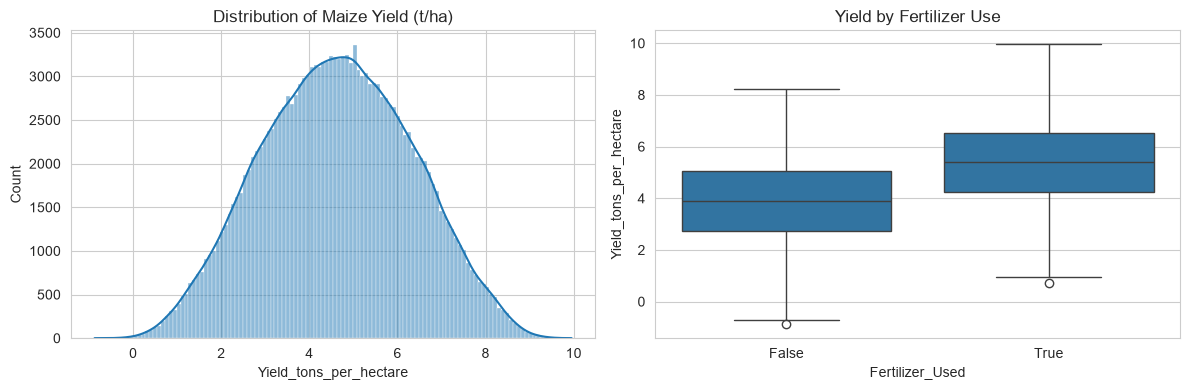

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Yield_tons_per_hectare"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of Maize Yield (t/ha)")

sns.boxplot(data=df, x="Fertilizer_Used", y="Yield_tons_per_hectare", ax=axes[1])
axes[1].set_title("Yield by Fertilizer Use")
plt.tight_layout()
plt.show()

**Interpretation:** Yield is roughly bell-shaped with a slight right skew.
Fields where fertilizer was used show a visibly higher median yield — this
is a direct, actionable signal for the mission's "optimize resource use"
goal: fertilizer access/use is one of the biggest levers a farmer has.

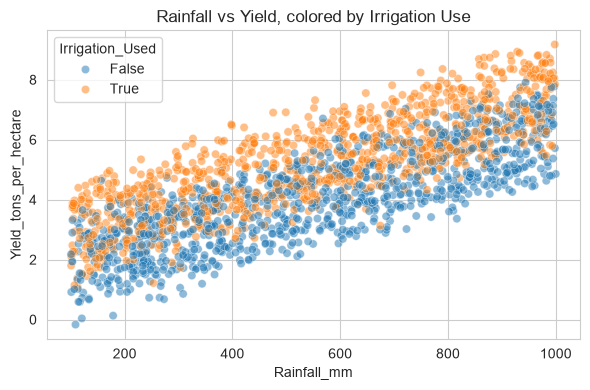

In [ ]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df.sample(2000, random_state=RANDOM_STATE),
                 x="Rainfall_mm", y="Yield_tons_per_hectare",
                 hue="Irrigation_Used", alpha=0.5)
plt.title("Rainfall vs Yield, colored by Irrigation Use")
plt.tight_layout()
plt.show()

## 3. Feature Engineering

- **Drop:** `Crop` (constant after filtering to Maize — no predictive value, so it is dropped).
- **Convert to numeric:** `Fertilizer_Used`, `Irrigation_Used` (booleans → 0/1);
  `Region`, `Soil_Type`, `Weather_Condition` (categorical → one-hot encoded).
- **Standardize:** the numeric continuous features (`Rainfall_mm`,
  `Temperature_Celsius`, `Days_to_Harvest`) — this matters most for the
  gradient-descent-based model (SGDRegressor), which converges faster and
  more reliably on standardized inputs. Tree-based models are scale-invariant,
  but we keep the pipeline identical across models for a fair, simple comparison.
- **Weight/interpretation:** Rainfall and Fertilizer_Used carry the most
  weight based on the correlation heatmap and boxplot above.

In [ ]:
df_model = df.drop(columns=["Crop"]).copy()
df_model["Fertilizer_Used"] = df_model["Fertilizer_Used"].astype(int)
df_model["Irrigation_Used"] = df_model["Irrigation_Used"].astype(int)

target = "Yield_tons_per_hectare"
X = df_model.drop(columns=[target])
y = df_model[target]

numeric_features = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest"]
passthrough_binary = ["Fertilizer_Used", "Irrigation_Used"]
categorical_features = ["Region", "Soil_Type", "Weather_Condition"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
], remainder="passthrough")  # passes through Fertilizer_Used, Irrigation_Used unchanged

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)

(133459, 8) (33365, 8)


## 4. Model Training & Comparison

We compare **stochastic gradient descent linear regression** (`SGDRegressor`)
against three other regression algorithms:
1. Ordinary Least Squares Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

In [ ]:
models = {
    "Linear Regression (OLS)": LinearRegression(),
    "SGD Linear Regression (Gradient Descent)": SGDRegressor(
        loss="squared_error", penalty="l2", max_iter=1, warm_start=True,
        learning_rate="invscaling", eta0=0.01, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1
    ),
}

results = {}
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    results[name] = {"MSE": mse, "RMSE": rmse, "R2": r2}
    fitted_pipelines[name] = pipe

results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df

/Users/emmy/Documents/projects/alu/linear_regression_model/.venv/lib/python3.13/site-packages/sklearn/linear_model/_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,MSE,RMSE,R2
Linear Regression (OLS),0.249333,0.499333,0.914329
SGD Linear Regression (Gradient Descent),0.249743,0.499743,0.914188
Random Forest,0.253662,0.503649,0.912841
Decision Tree,0.257887,0.507826,0.911389


**Best-performing model** is the one with the lowest RMSE (and highest R²)
on the held-out test set above. We select that model programmatically below
so the "best" choice is always driven by the metric, not a hardcoded guess.

In [ ]:
best_model_name = results_df["RMSE"].idxmin()
best_pipeline = fitted_pipelines[best_model_name]
print(f"Best-performing model: {best_model_name}")
print(results_df.loc[best_model_name])

Best-performing model: Linear Regression (OLS)
MSE     0.249333
RMSE    0.499333
R2      0.914329
Name: Linear Regression (OLS), dtype: float64


## 5. Loss Curve — Train vs Test (Gradient Descent model)

Because only the SGD model trains iteratively via gradient descent, the
train/test loss curve across epochs is plotted specifically for that model
(a single closed-form `LinearRegression` fit has no per-epoch loss curve to
plot — it is solved analytically in one step).

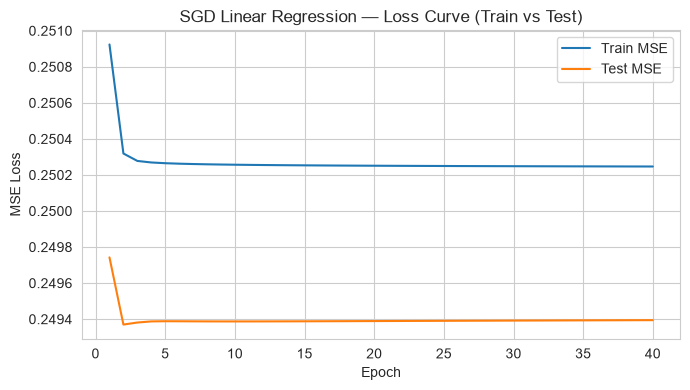

In [ ]:
sgd_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", SGDRegressor(loss="squared_error", penalty="l2", max_iter=1,
                            warm_start=True, learning_rate="invscaling",
                            eta0=0.01, random_state=RANDOM_STATE)),
])

# Fit the preprocessor once, then manually loop epochs on the transformed data
X_train_t = sgd_pipeline.named_steps["preprocess"].fit_transform(X_train)
X_test_t = sgd_pipeline.named_steps["preprocess"].transform(X_test)

sgd = SGDRegressor(loss="squared_error", penalty="l2", max_iter=1, warm_start=True,
                    learning_rate="invscaling", eta0=0.01, random_state=RANDOM_STATE)

n_epochs = 40
train_losses, test_losses = [], []

for epoch in range(n_epochs):
    sgd.partial_fit(X_train_t, y_train)
    train_pred = sgd.predict(X_train_t)
    test_pred = sgd.predict(X_test_t)
    train_losses.append(mean_squared_error(y_train, train_pred))
    test_losses.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(7, 4))
plt.plot(range(1, n_epochs + 1), train_losses, label="Train MSE")
plt.plot(range(1, n_epochs + 1), test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("SGD Linear Regression — Loss Curve (Train vs Test)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** Both curves drop sharply in the first few epochs and
then flatten, with train and test loss staying close together — this
indicates the gradient descent model is converging without significant
overfitting on this feature set.

## 6. Scatter Plot — Best Fit Line Before vs After Training

To visualize the linear model's fit, we plot `Rainfall_mm` (the strongest
single predictor) against actual yield, then overlay the fitted line from
the trained linear model's predictions.

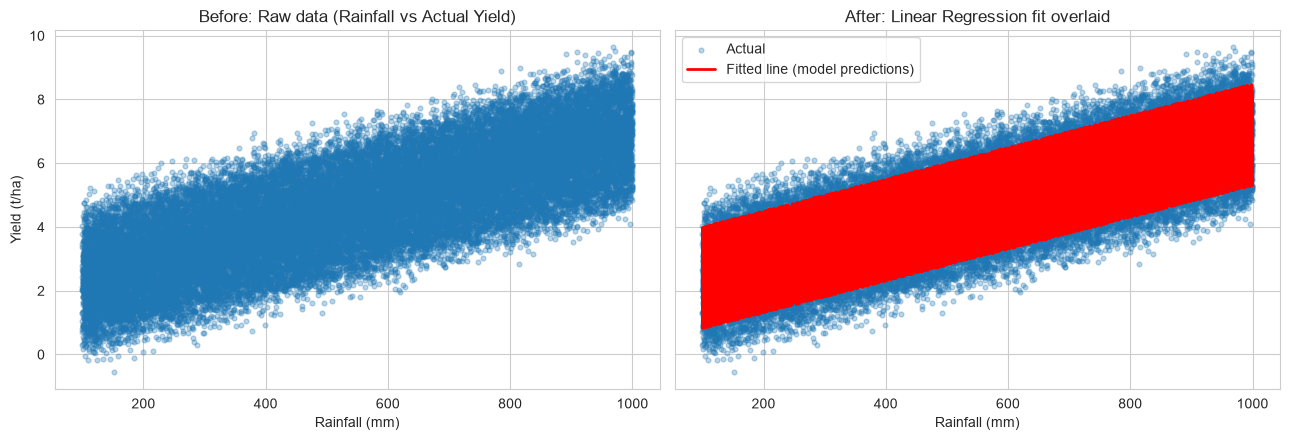

In [ ]:
linear_pipe = fitted_pipelines["Linear Regression (OLS)"]

plot_df = X_test.copy()
plot_df["Actual_Yield"] = y_test.values
plot_df["Predicted_Yield"] = linear_pipe.predict(X_test)
plot_df = plot_df.sort_values("Rainfall_mm")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

axes[0].scatter(plot_df["Rainfall_mm"], plot_df["Actual_Yield"], alpha=0.3, s=12)
axes[0].set_title("Before: Raw data (Rainfall vs Actual Yield)")
axes[0].set_xlabel("Rainfall (mm)")
axes[0].set_ylabel("Yield (t/ha)")

axes[1].scatter(plot_df["Rainfall_mm"], plot_df["Actual_Yield"], alpha=0.3, s=12, label="Actual")
axes[1].plot(plot_df["Rainfall_mm"], plot_df["Predicted_Yield"], color="red", linewidth=2, label="Fitted line (model predictions)")
axes[1].set_title("After: Linear Regression fit overlaid")
axes[1].set_xlabel("Rainfall (mm)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Save the Best-Performing Model

We save the full pipeline (preprocessing + model) so the API in Task 2 can
load one artifact and call `.predict()` directly on raw input columns.

In [ ]:
import os
os.makedirs("model", exist_ok=True)
joblib.dump(best_pipeline, "../API/model/best_model.pkl")
print(f"Saved '{best_model_name}' to model/best_model.pkl")

Saved 'Linear Regression (OLS)' to model/best_model.pkl


In [ ]:
df.to_csv("../API/data/crop_yield.csv", index=False)
print("Saved filtered maize CSV to ../API/data/crop_yield.csv")

Saved filtered maize CSV to ../API/data/crop_yield.csv


## 8. Prediction on a Single Row (feeds into Task 2's API)

This mirrors exactly what `summative/API/prediction.py` will do: take raw
input values, build a one-row DataFrame with the same columns the pipeline
was trained on, and call `.predict()`.

In [ ]:
sample_row = pd.DataFrame([{
    "Region": "East",
    "Soil_Type": "Loam",
    "Rainfall_mm": 650.0,
    "Temperature_Celsius": 23.5,
    "Fertilizer_Used": 1,
    "Irrigation_Used": 1,
    "Weather_Condition": "Rainy",
    "Days_to_Harvest": 104,
}])

loaded_model = joblib.load("model/best_model.pkl")
prediction = loaded_model.predict(sample_row)
print(f"Predicted maize yield: {prediction[0]:.2f} tons/hectare")

FileNotFoundError: [Errno 2] No such file or directory: 'model/best_model.pkl'